# Influenza Spatio-Temporal Transformer: architecture diagram (A4 portrait)

Run the cells in order. The figure is exactly A4 portrait (8.27 x 11.69 in) and is also saved as PDF and PNG.

In [1]:
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from textwrap import fill

A4_W_IN, A4_H_IN = 8.27, 11.69  # A4 portrait, inches


def draw_canonical_transformer_architecture(n_layers=3, n_heads=4, d_model=128, dff=256,
                                            save_prefix="transformer_architecture_A4", show=True):
    # Figure is exactly A4 portrait. Data units are square (1 unit ~ 0.41 in), and all
    # font sizes are real point sizes, so what you see is what prints on A4 (no rescaling).
    fig = plt.figure(figsize=(A4_W_IN, A4_H_IN), dpi=300)
    ax = fig.add_axes([0, 0, 1, 1])
    W = 20.0
    H = W * A4_H_IN / A4_W_IN
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.axis("off")

    # ---- palette (Vaswani-style) ------------------------------------------------
    c_mha, c_norm, c_ffn = "#ffe6cc", "#dae8fc", "#fff2cc"
    c_embed, c_film, c_trend = "#d5e8d4", "#e1d5e7", "#f8cecc"
    c_stack_bg, c_out = "#f6f6f6", "#e6e6e6"
    LINE, FILM_C, TREND_C, KV_C = "#333333", "#805b9a", "#b03a3a", "#1f497d"

    # ---- helpers ------------------------------------------------------------------
    def box(x, y, title, sub="", note="", w=4.6, h=0.85, fc="#f2f2f2", fs=6.8, fs_sub=6.0):
        ax.add_patch(patches.FancyBboxPatch(
            (x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.12",
            fc=fc, ec=LINE, lw=0.8, zorder=3))
        lines = [(title, fs, "bold", "normal", "#111111")]
        for s in (sub.split("\n") if sub else []):
            lines.append((s, fs_sub, "normal", "normal", "#222222"))
        if note:
            lines.append((note, fs_sub - 0.4, "normal", "italic", "#555555"))
        step = 0.32
        y0 = y + (len(lines) - 1) * step / 2
        for i, (t, f, wt, st, col) in enumerate(lines):
            ax.text(x, y0 - i * step, t, ha="center", va="center", fontsize=f,
                    fontweight=wt, fontstyle=st, color=col, zorder=4)

    def plus(x, y, r=0.27):
        ax.add_patch(plt.Circle((x, y), r, fc="white", ec=LINE, lw=0.9, zorder=4))
        ax.text(x, y, "+", ha="center", va="center", fontsize=9, fontweight="bold", zorder=5)

    def path(pts, color=LINE, ls="-", lw=0.9, arrow=True, L=0.26, Wd=0.09):
        pts = list(pts)
        if arrow:
            (x0, y0), (x1, y1) = pts[-2], pts[-1]
            d = math.hypot(x1 - x0, y1 - y0)
            ux, uy = (x1 - x0) / d, (y1 - y0) / d
            bx, by = x1 - ux * L, y1 - uy * L
            ax.add_patch(patches.Polygon(
                [(x1, y1), (bx - uy * Wd, by + ux * Wd), (bx + uy * Wd, by - ux * Wd)],
                closed=True, fc=color, ec=color, lw=0.3, zorder=3))
            pts[-1] = (bx, by)
        xs, ys = zip(*pts)
        ax.plot(xs, ys, color=color, ls=ls, lw=lw, zorder=2)

    def region(x, y, w, h, fc, ec, lw=1.0, ls="--"):
        ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.25",
                                            fc=fc, ec=ec, lw=lw, ls=ls, zorder=1))

    # ---- layout constants -------------------------------------------------------
    XE, XD, BW = 4.8, 15.4, 4.6         # encoder / decoder column centres, block width
    X_TREND, X_BUS, X_KV = 9.65, 10.45, 11.3   # vertical "buses" in the centre gap
    Y_ROW = 8.85                         # embedding row of both towers

    # ==============================================================================
    # 1. SPATIO-TEMPORAL CONTEXT (bottom centre)
    # ==============================================================================
    region(3.9, 0.25, 12.2, 7.15, "#faf5fc", "#9673a6")
    ax.text(10.0, 0.55, "Spatio-Temporal Context  (one shared FiLM layer)", ha="center",
            va="center", fontsize=7, fontweight="bold", color="#5c3566")

    box(6.4, 1.35, "encoder_time_input", "[Δmonths, sin, cos]", w=3.8, h=0.8, fc=c_film, fs=6.4)
    box(10.2, 1.35, "encoder_zone_input", "[zone ID]", w=3.0, h=0.8, fc=c_film, fs=6.2)
    box(13.6, 1.35, "encoder_clade_input", "[clade ID]", w=3.1, h=0.8, fc=c_film, fs=6.2)

    box(6.4, 2.45, "Dense(128, GELU)", "time_proj", w=3.8, h=0.8, fc=c_film)
    box(10.2, 2.45, "Embedding(zones, 32)", "zone_embed", w=3.0, h=0.8, fc=c_film, fs=6.2)
    box(13.6, 2.45, "Embedding(clades, 32)", "clade_embed", w=3.1, h=0.8, fc=c_film, fs=6.2)
    for x in (6.4, 10.2, 13.6):
        path([(x, 1.75), (x, 2.05)])

    box(6.4, 3.55, "TimeDecayLayer", "× exp(−λ·age),  λ = 0.06", w=3.8, h=0.8, fc=c_film)
    path([(6.4, 2.85), (6.4, 3.15)])

    box(10.0, 4.6, "Concatenate  [128 + 32 + 32]", w=8.2, h=0.56, fc=c_film)
    path([(6.4, 3.95), (6.4, 4.32)])
    path([(10.2, 2.85), (10.2, 4.32)])
    path([(13.6, 2.85), (13.6, 4.32)])

    box(10.0, 5.55, "Dense 64 → Dense 128 (GELU)", "st_context  ·  GaussianNoise(0.05)",
        w=6.6, h=0.8, fc=c_film)
    path([(10.0, 4.88), (10.0, 5.15)])

    box(X_BUS, 6.7, "Shared SpatioTemporalFiLM", "γ = σ(Dense(ctx)),   β = Dense(ctx)",
        w=5.4, h=0.8, fc="#d5b8ff")
    path([(10.0, 5.95), (10.0, 6.3)])

    # FiLM context bus (dashed purple)
    path([(X_BUS, 7.1), (X_BUS, 15.6)], FILM_C, "--", arrow=False)
    ax.text(X_BUS + 0.14, 10.0, "FiLM  γ, β", rotation=90, ha="left", va="center",
            fontsize=6, color=FILM_C, fontweight="bold")

    # ==============================================================================
    # 2. ENCODER (left)
    # ==============================================================================
    enc_xs = [1.35, 3.65, 5.95, 8.25]
    enc_cfg = [("Token Emb.", "anchor seq. × √d", "encoder_input", c_embed),
               ("Position Emb.", "Embedding(600)", "position_input_enc", c_embed),
               ("Epitope Emb.", "Embedding(2)", "epitope_input", c_embed),
               ("Prop. Proj.", "Dense 16 → 128", "proportion_input", c_trend)]
    for x, (t, s, n, c) in zip(enc_xs, enc_cfg):
        box(x, Y_ROW, t, s, n, w=2.2, h=1.15, fc=c, fs=6.4, fs_sub=5.8)
        path([(x, Y_ROW + 0.575), (x, 9.62)], arrow=False)
    path([(enc_xs[0], 9.62), (enc_xs[-1], 9.62)], arrow=False)
    path([(7.0, 9.62), (7.0, 10.02)])
    plus(7.0, 10.3)

    # reference (baseline) branch
    box(2.6, 10.3, "Ref. Embedding", "last-6-month consensus", "reference_input",
        w=3.0, h=1.05, fc=c_embed, fs=6.4, fs_sub=5.8)
    box(2.6, 11.6, "FiLM  (γ·x + β)", "reference branch", w=3.0, h=0.8, fc=c_film)
    box(7.0, 11.6, "FiLM  (γ·x + β)", "sequence branch", w=3.2, h=0.8, fc=c_film)
    path([(2.6, 10.825), (2.6, 11.2)])
    path([(7.0, 10.58), (7.0, 11.2)])

    # FiLM context comb into the two encoder FiLM blocks
    path([(X_BUS, 12.35), (2.2, 12.35)], FILM_C, "--", arrow=False)
    path([(7.5, 12.35), (7.5, 12.0)], FILM_C, "--")
    path([(2.2, 12.35), (2.2, 12.0)], FILM_C, "--")

    # fusion gate
    box(XE, 13.2, "Sigmoid Fusion Gate + LayerNorm", "enc + σ(W[enc; ref]) ⊙ ref",
        w=7.2, h=0.9, fc=c_norm)
    path([(6.5, 12.0), (6.5, 12.75)])
    path([(3.2, 12.0), (3.2, 12.75)])

    # encoder stack
    region(XE - 2.9, 14.1, 5.8, 5.55, c_stack_bg, "#666666", lw=1.1)
    ax.text(1.5, 16.85, f"N = {n_layers} ×", rotation=90, ha="center", va="center",
            fontsize=9, fontweight="bold", color="#333333")
    box(XE, 15.0, "Multi-Head Attention", f"Self-attention, {n_heads} heads", fc=c_mha)
    box(XE, 16.3, "Add & Norm", "LayerNorm(x + Dropout(f(x)))", h=0.7, fc=c_norm)
    box(XE, 17.6, "Feed Forward", f"Dense({dff}, GELU) → Dense({d_model})", fc=c_ffn)
    box(XE, 18.9, "Add & Norm", "LayerNorm(x + Dropout(f(x)))", h=0.7, fc=c_norm)

    path([(XE, 13.65), (XE, 14.575)])                       # into MHA (Q = K = V)
    path([(XE - 0.9, 14.25), (XE - 0.9, 14.575)])
    path([(XE + 0.9, 14.25), (XE + 0.9, 14.575)])
    path([(XE - 0.9, 14.25), (XE + 0.9, 14.25)], arrow=False)
    path([(XE, 13.95), (2.2, 13.95), (2.2, 16.3), (XE - BW / 2, 16.3)])   # residual 1
    path([(XE, 15.425), (XE, 15.95)])
    path([(XE, 16.65), (XE, 17.175)])
    path([(XE, 16.9), (2.2, 16.9), (2.2, 18.9), (XE - BW / 2, 18.9)])      # residual 2
    path([(XE, 18.025), (XE, 18.55)])

    # encoder memory -> decoder cross-attention (K, V)
    path([(XE, 19.25), (XE, 20.3), (X_KV, 20.3), (X_KV, 16.9), (XD - BW / 2, 16.9)], KV_C, lw=1.1)
    ax.text(X_KV + 0.3, 18.6, "Encoder memory (K, V)", rotation=90, ha="center", va="center",
            fontsize=6.2, fontweight="bold", color=KV_C)

    # ==============================================================================
    # 3. DECODER (right)
    # ==============================================================================
    box(13.45, Y_ROW, "Token Emb.", "learned, × √d", "decoder_input (shifted right)",
        w=3.8, h=1.15, fc=c_embed, fs=6.4, fs_sub=5.8)
    box(17.45, Y_ROW, "Position Emb.", "Embedding(600)", "position_input_dec",
        w=3.9, h=1.15, fc=c_embed, fs=6.4, fs_sub=5.8)
    path([(13.45, Y_ROW + 0.575), (13.45, 9.62)], arrow=False)
    path([(17.45, Y_ROW + 0.575), (17.45, 9.62)], arrow=False)
    path([(13.45, 9.62), (17.45, 9.62)], arrow=False)
    path([(XD, 9.62), (XD, 9.93)])
    plus(XD, 10.2)
    box(XD, 11.2, "FiLM  (γ·x + β)", "decoder input", fc=c_film)
    path([(XD, 10.47), (XD, 10.8)])
    path([(X_BUS, 11.2), (XD - BW / 2, 11.2)], FILM_C, "--")

    region(XD - 2.7, 11.85, 5.4, 9.6, c_stack_bg, "#666666", lw=1.1)
    ax.text(18.75, 16.6, f"N = {n_layers} ×", rotation=270, ha="center", va="center",
            fontsize=9, fontweight="bold", color="#333333")
    XB = XD + 2.55   # residual-bypass lane (right side of the decoder)

    box(XD, 13.0, "Masked Multi-Head Attention", f"Self-attention, {n_heads} heads", fc=c_mha)
    box(XD, 14.3, "Add & Norm", "LayerNorm(x + Dropout(f(x)))", h=0.7, fc=c_norm)
    box(XD, 15.6, "FiLM  (γ·x + β)", "spatio-temporal context", h=0.8, fc=c_film)
    box(XD, 16.9, "Multi-Head Attention", f"Cross-attention, {n_heads} heads", fc=c_mha)
    box(XD, 18.2, "Add & Norm", "LayerNorm(x + Dropout(f(x)))", h=0.7, fc=c_norm)
    box(XD, 19.5, "Feed Forward", f"Dense({dff}, GELU) → Dense({d_model})", fc=c_ffn)
    box(XD, 20.8, "Add & Norm", "LayerNorm(x + Dropout(f(x)))", h=0.7, fc=c_norm)

    path([(XD, 11.6), (XD, 12.575)])
    path([(XD - 0.9, 12.25), (XD - 0.9, 12.575)])
    path([(XD + 0.9, 12.25), (XD + 0.9, 12.575)])
    path([(XD - 0.9, 12.25), (XD + 0.9, 12.25)], arrow=False)
    path([(XD, 11.75), (XB, 11.75), (XB, 14.3), (XD + BW / 2, 14.3)])      # residual 1
    path([(XD, 13.425), (XD, 13.95)])
    path([(XD, 14.65), (XD, 15.2)])
    path([(X_BUS, 15.6), (XD - BW / 2, 15.6)], FILM_C, "--")
    path([(XD, 16.0), (XD, 16.475)])                                       # query
    path([(XD, 16.2), (XB, 16.2), (XB, 18.2), (XD + BW / 2, 18.2)])        # residual 2
    path([(XD, 17.325), (XD, 17.85)])
    path([(XD, 18.55), (XD, 19.075)])
    path([(XD, 18.8), (XB, 18.8), (XB, 20.8), (XD + BW / 2, 20.8)])        # residual 3
    path([(XD, 19.925), (XD, 20.45)])

    # ==============================================================================
    # 4. OUTPUT HEAD + LINEAR TREND SKIP CONNECTION
    # ==============================================================================
    box(XD, 22.4, "Linear Projection", "nn_logits: Dense(vocab)", fc="#f5f5f5")
    path([(XD, 21.15), (XD, 21.975)])
    plus(XD, 23.5)
    path([(XD, 22.825), (XD, 23.23)])

    box(9.9, 21.8 + 0.4, "Linear Trend Projection", "trend_residual_proj: Dense(vocab)",
        w=4.0, h=0.8, fc=c_trend)
    box(9.9, 23.5, "Sequence Alignment", "align_trend_shift: x[:, 1:, :]", w=4.0, h=0.8, fc=c_trend)
    path([(enc_xs[-1] + 1.1, Y_ROW), (X_TREND, Y_ROW), (X_TREND, 21.8)], TREND_C, lw=1.2)
    path([(9.9, 22.6), (9.9, 23.1)], TREND_C, lw=1.2)
    path([(11.9, 23.5), (XD - 0.27, 23.5)], TREND_C, lw=1.2)
    ax.text(X_TREND - 0.25, 15.0, "Direct trend bypass (frequency, slope)", rotation=90,
            ha="center", va="center", fontsize=6.2, fontweight="bold", color=TREND_C)

    box(XD, 24.6, "Softmax / Cross-Entropy Loss", "weighted_masked_loss", fc=c_out)
    path([(XD, 23.77), (XD, 24.175)])
    box(XD, 25.75, "Output Probabilities", "next-season amino-acid sequence", h=0.8, fc=c_norm)
    path([(XD, 25.025), (XD, 25.35)])

    # ==============================================================================
    # TITLE, LEGEND, NOTES
    # ==============================================================================
    ax.text(10, 27.45, "Influenza Spatio-Temporal Sequence-to-Sequence Transformer",
            ha="center", va="center", fontsize=11.5, fontweight="bold", color="#222222")
    ax.text(10, 26.85, "Adapted from the canonical Vaswani et al. architecture",
            ha="center", va="center", fontsize=7.5, color="#444444")

    ax.text(0.35, 7.05, "Legend", fontsize=7, fontweight="bold", va="center")
    items = [(c_embed, "Inputs / embeddings"), (c_mha, "Multi-head attention"),
             (c_norm, "Add & Norm / fusion"), (c_ffn, "Feed-forward"),
             (c_film, "Spatio-temporal / FiLM"), (c_trend, "Trend skip path")]
    for i, (c, t) in enumerate(items):
        yy = 6.45 - i * 0.5
        ax.add_patch(patches.Rectangle((0.35, yy - 0.16), 0.5, 0.32, fc=c, ec=LINE, lw=0.6, zorder=3))
        ax.text(1.0, yy, t, fontsize=6.2, va="center")
    for j, (c, ls, t) in enumerate([(LINE, "-", "Data flow"), (FILM_C, "--", "FiLM context (γ, β)"),
                                    (TREND_C, "-", "Trend bypass"), (KV_C, "-", "Encoder memory (K, V)")]):
        yy = 6.45 - (len(items) + j) * 0.5 - 0.1
        ax.plot([0.35, 0.85], [yy, yy], color=c, ls=ls, lw=1.1)
        ax.text(1.0, yy, t, fontsize=6.2, va="center")

    notes = ["encoder_input = consensus anchor of the first 6 months of the training window; "
             "reference_input = consensus of the last 6 months.",
             "One SpatioTemporalFiLM layer (shared weights) is applied at all four FiLM sites.",
             "The model outputs logits; softmax is applied inside the loss."]
    ax.text(16.35, 7.05, "Notes", fontsize=7, fontweight="bold", va="center")
    ax.text(16.35, 6.7, "\n\n".join(fill("• " + n, 31) for n in notes), fontsize=5.8,
            va="top", linespacing=1.25, color="#333333")

    if save_prefix:
        fig.savefig(f"{save_prefix}.pdf")                 # vector, prints sharply on A4
        fig.savefig(f"{save_prefix}.png", dpi=300)
    if show:
        plt.show()
    return fig


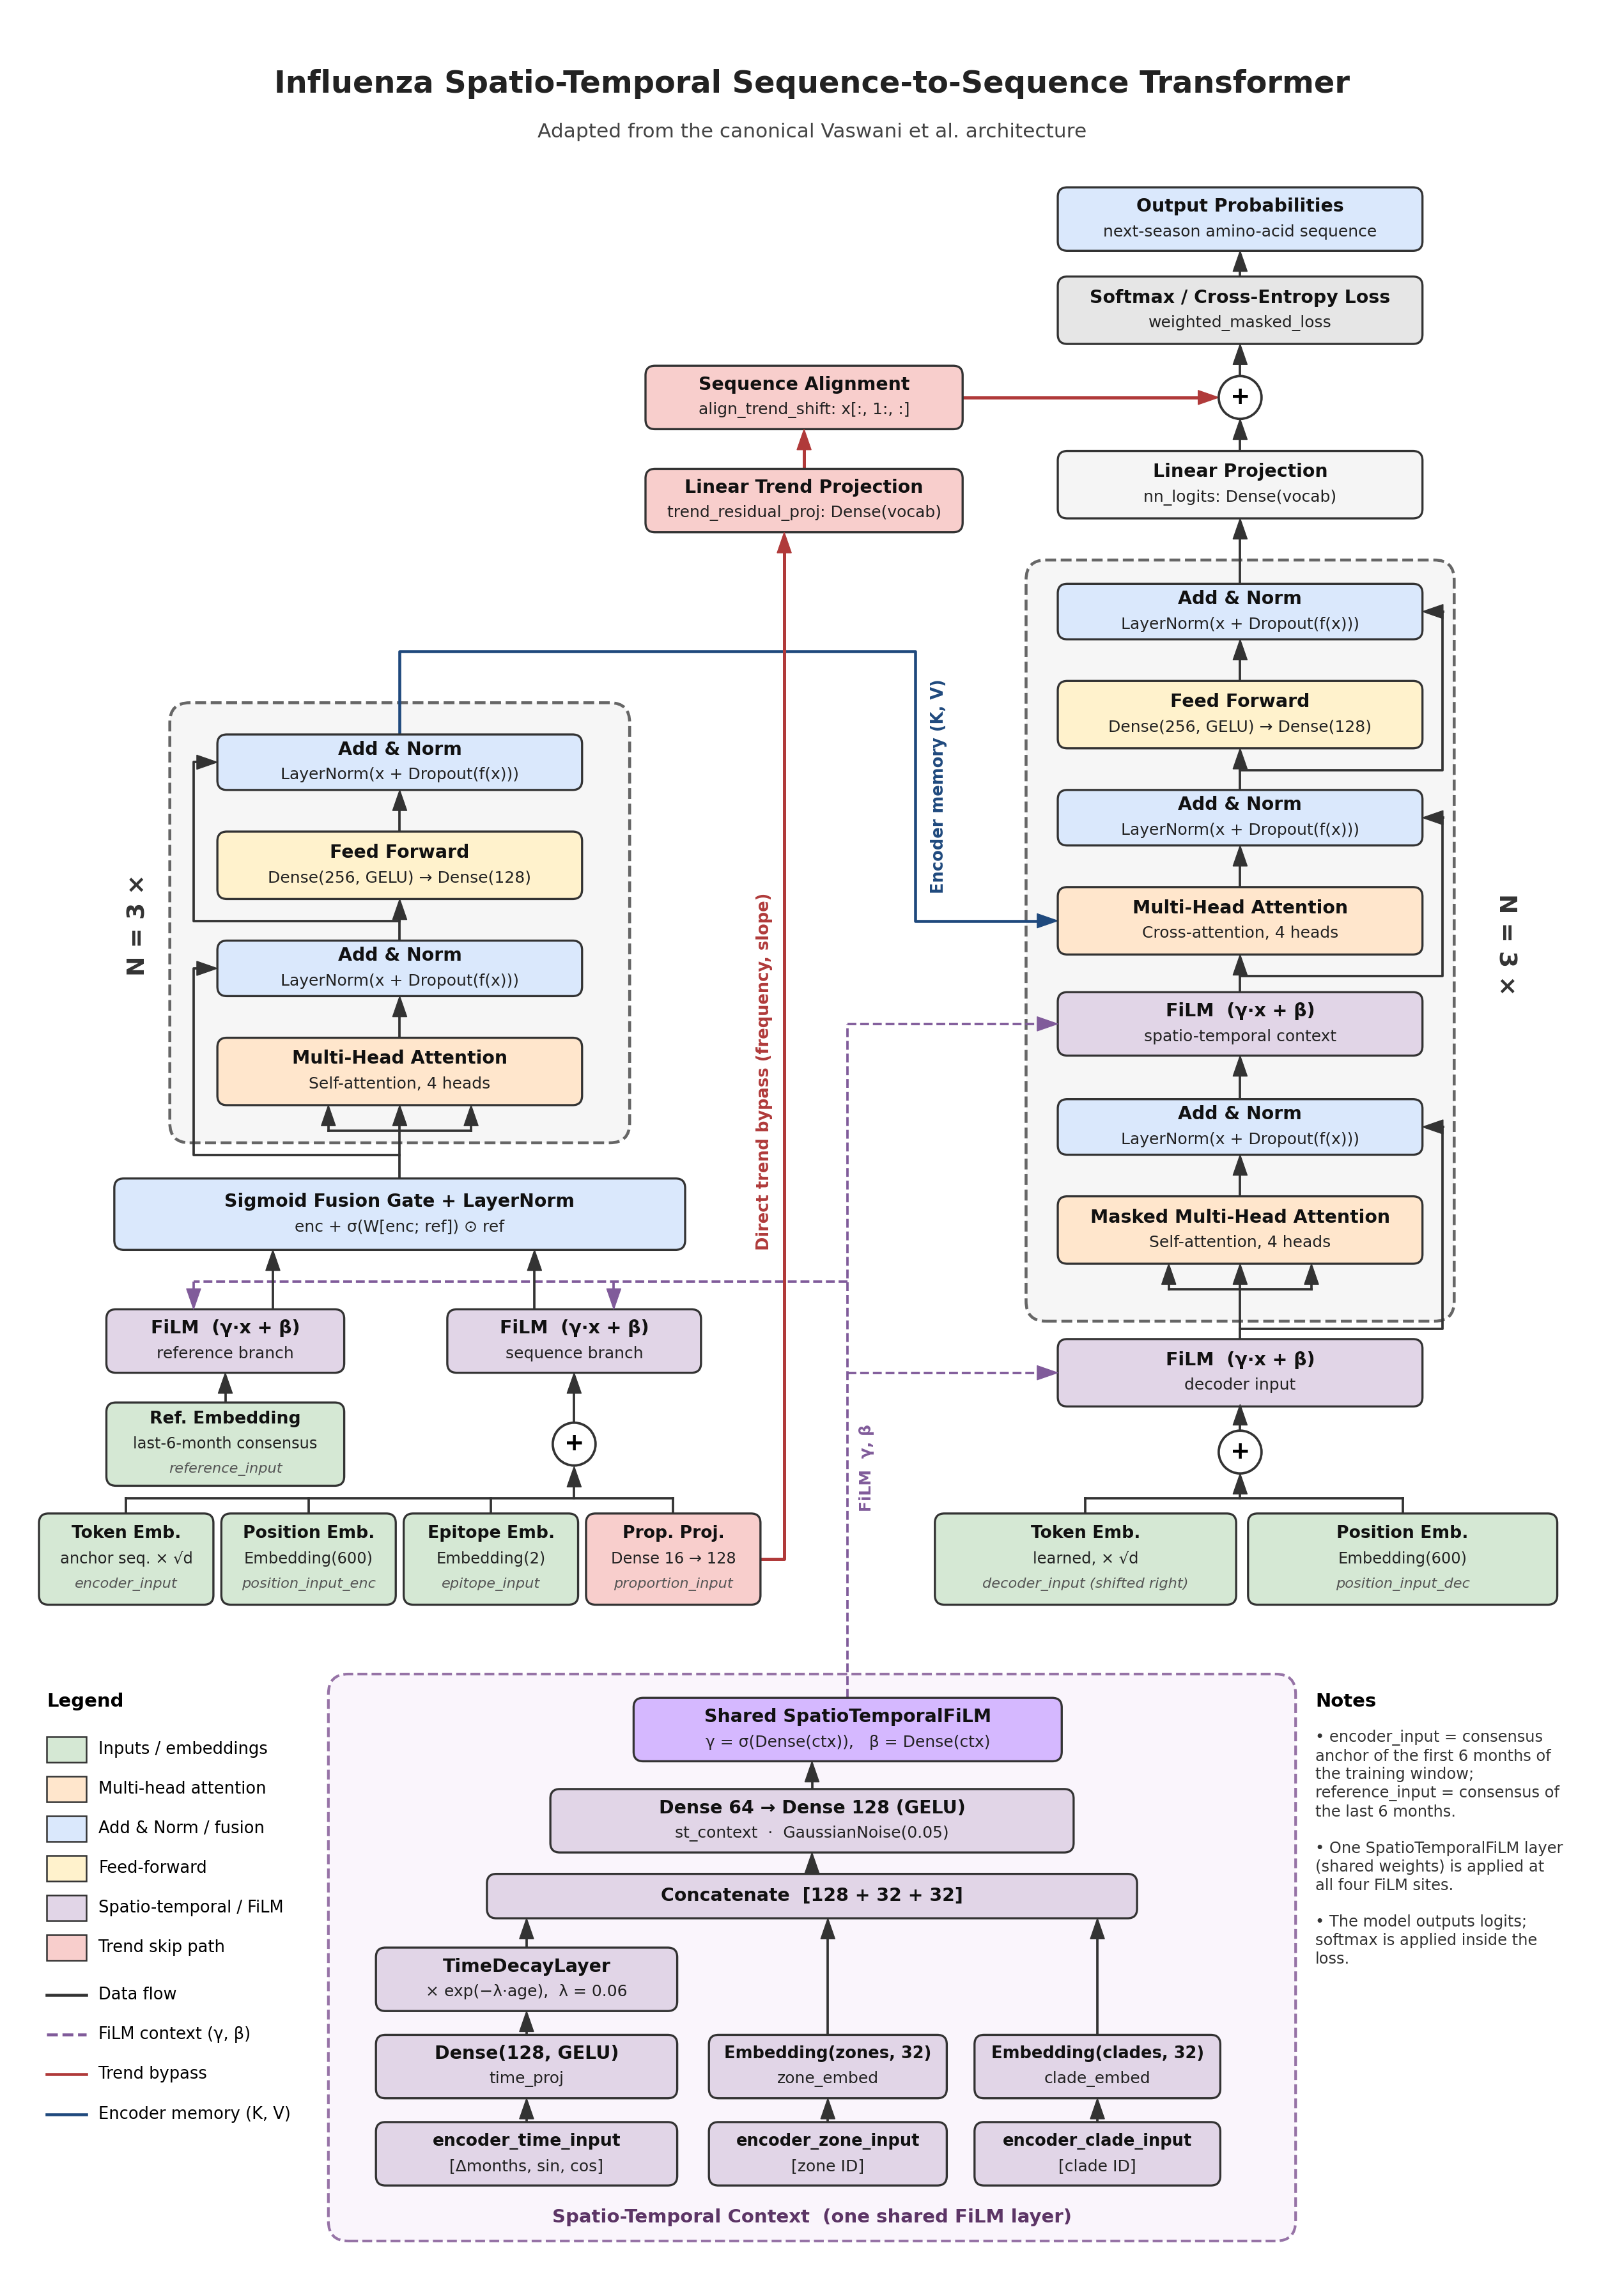

In [2]:
# Change n_layers / n_heads to match the variant you want to draw
fig = draw_canonical_transformer_architecture(n_layers=3, n_heads=4)

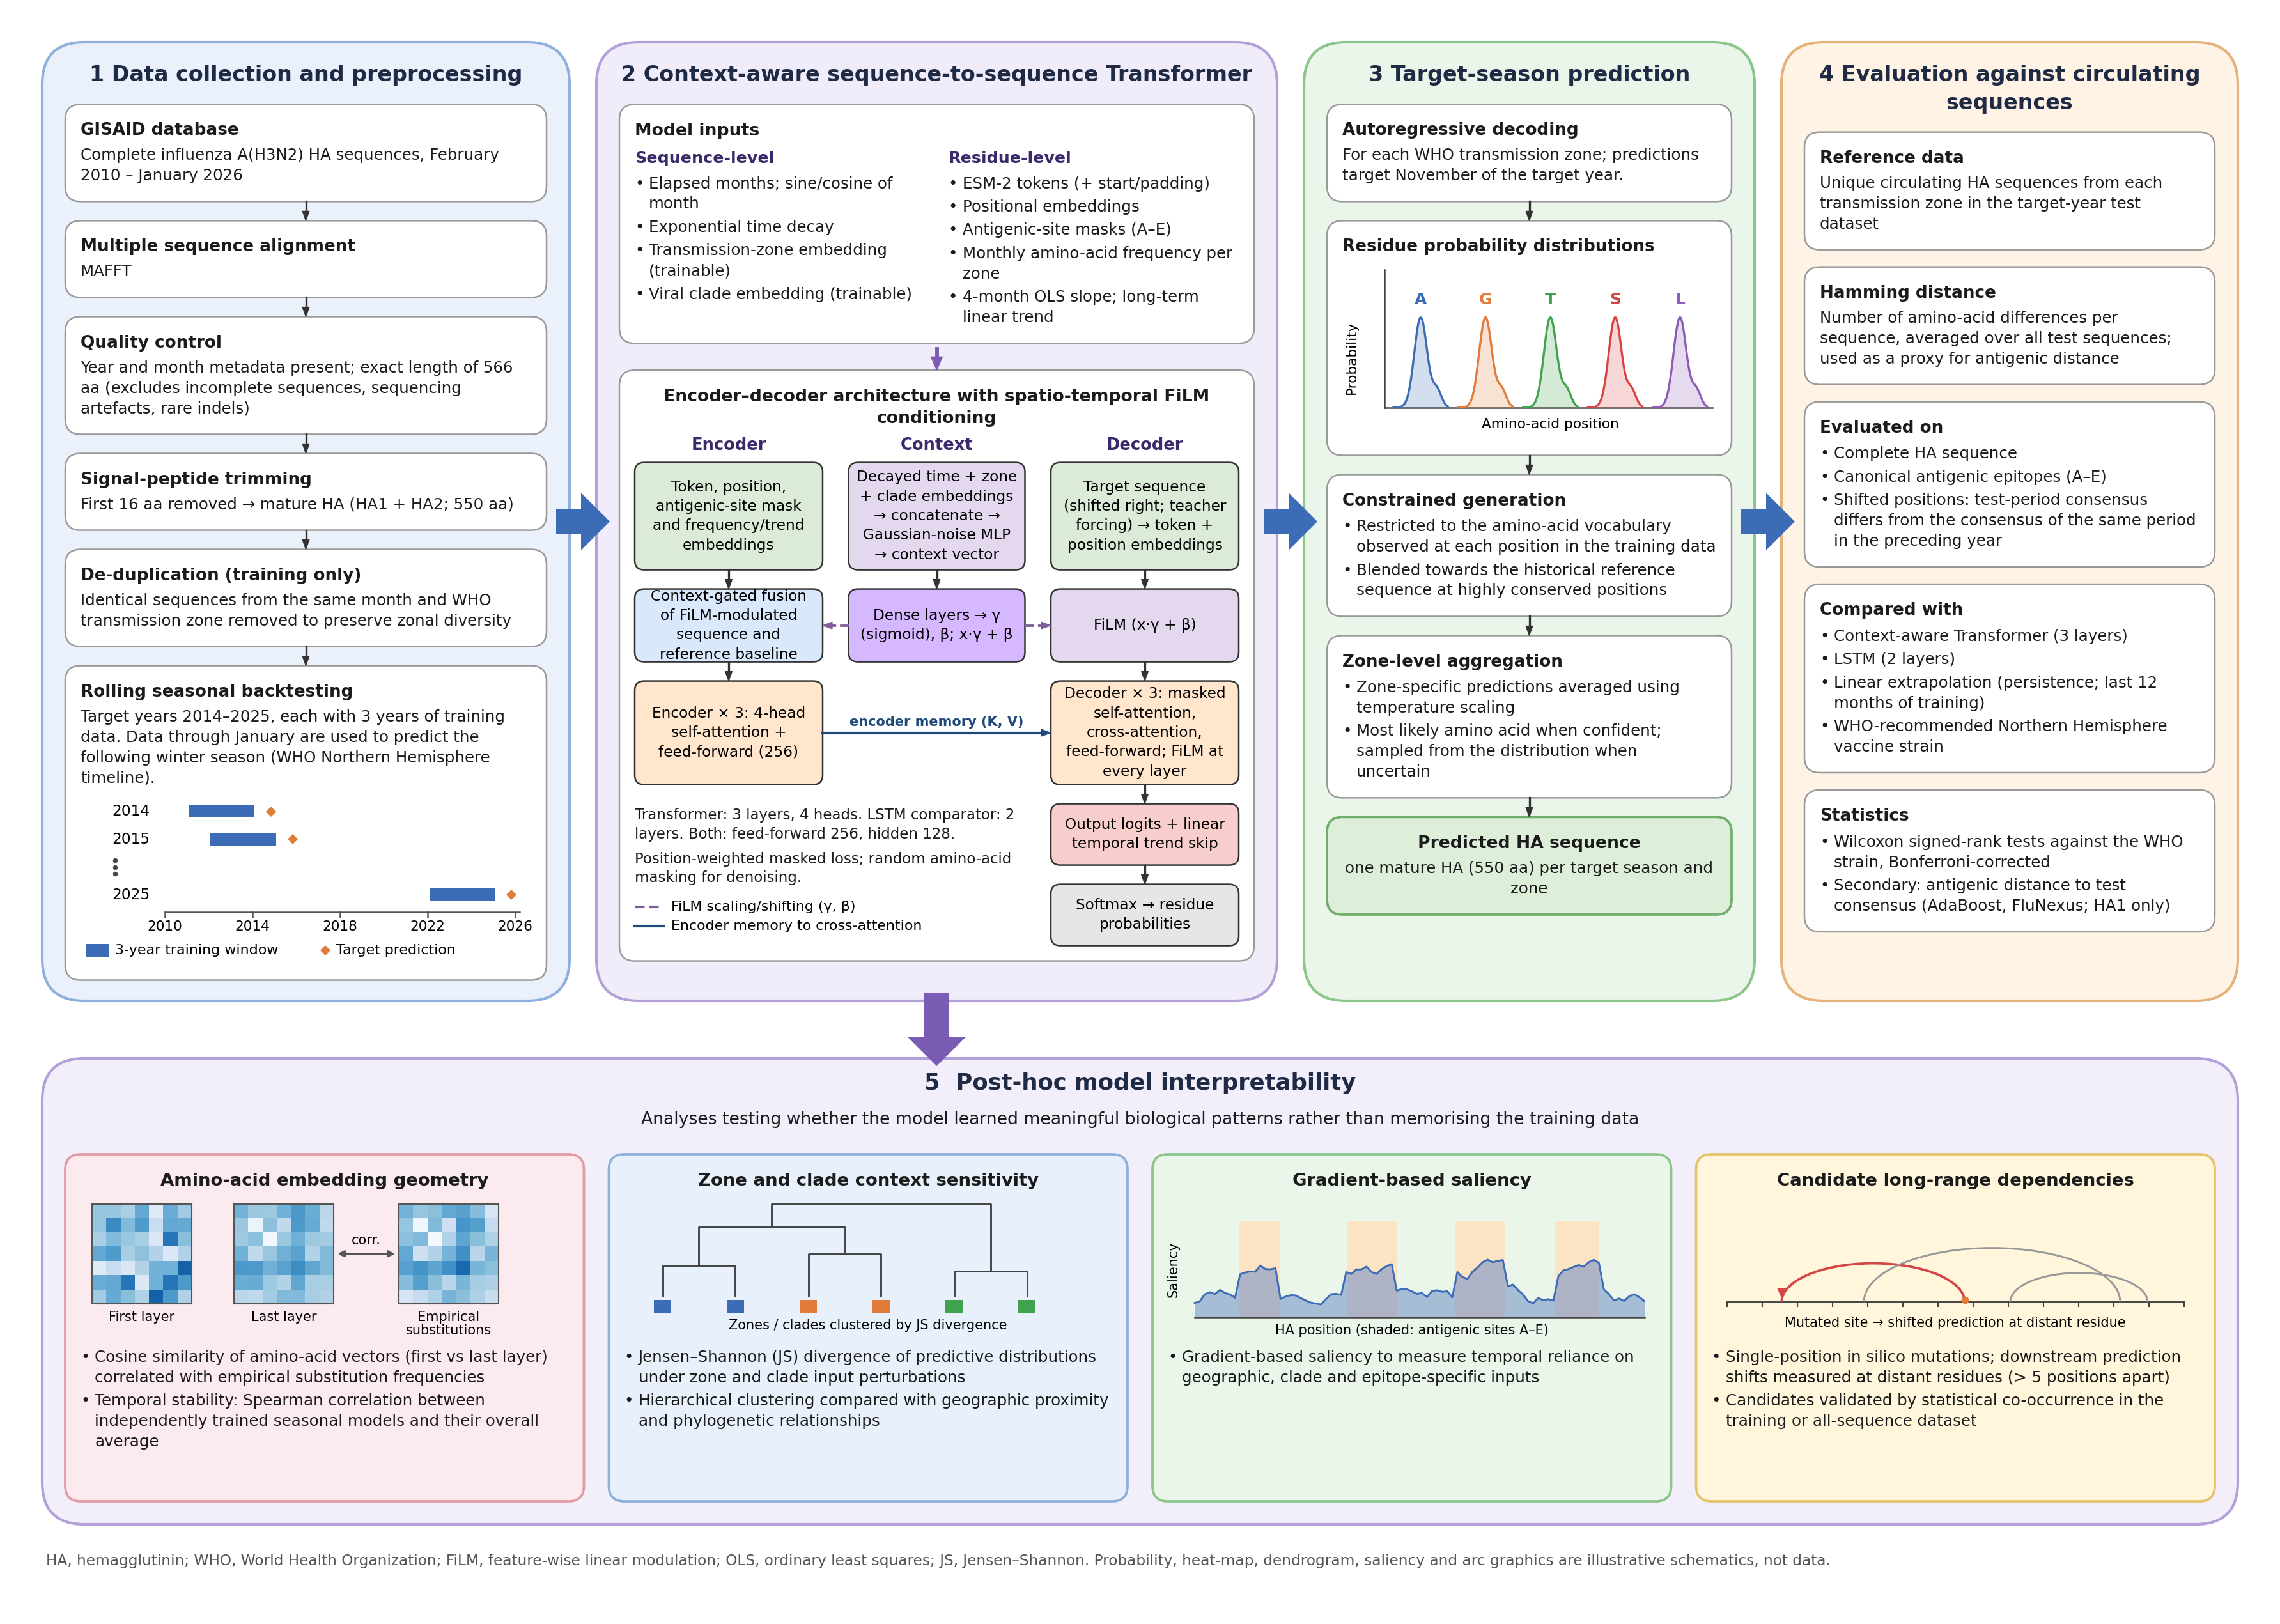

In [8]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.font_manager import FontProperties

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "pdf.fonttype": 42,        # embed editable text in the PDF
    "svg.fonttype": "none",
})


def draw_pipeline_overview(save_prefix="Figure1_pipeline_overview", show=True):
    """Figure 1: overview of the H3N2 HA forecasting pipeline (A4 landscape, 1 data unit = 0.1 in)."""
    W, H = 116.9, 82.7
    fig = plt.figure(figsize=(11.69, 8.27), dpi=300)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.axis("off")
    meas = FigureCanvasAgg(Figure(dpi=300)).get_renderer()

    TXT, EC, LINE = "#1b1b1b", "#9a9a9a", "#333333"
    BLUE, ORANGE, GREEN, RED, PURPLE = "#3B6CB5", "#E07B39", "#3FA34D", "#D64545", "#8E5BB5"
    FILM_C, KV_C = "#805b9a", "#1f497d"
    c_embed, c_film, c_attn, c_fuse, c_trend, c_out = "#DCEBD8", "#E3D8EE", "#FFE6CC", "#DAE8FC", "#F8CECC", "#E6E6E6"

    # ------------------------------------------------------------------ text engine
    def text_w(s, fs, wt="normal"):
        fp = FontProperties(size=fs, weight=wt)
        w, _, _ = meas.get_text_width_height_descent(s, fp, ismath=False)
        return w / 300.0 * 10.0

    def lh(fs):
        return fs * 1.3 / 7.2

    def wrap(s, width, fs, wt="normal"):
        out = []
        for para in s.split("\n"):
            cur = ""
            for wd in para.split(" "):
                t = (cur + " " + wd).strip()
                if not cur or text_w(t, fs, wt) <= width:
                    cur = t
                else:
                    out.append(cur)
                    cur = wd
            out.append(cur)
        return out

    def P(t, fs=5.9, wt="normal", c=TXT, b=False, st="normal", after=0.15, ha="left"):
        return dict(t=t, fs=fs, wt=wt, c=c, b=b, st=st, after=after, ha=ha)

    def G(h, fn):
        return dict(sp=h, fn=fn, after=0.0)

    def layout(parts, inner):
        items, hh = [], 0.0
        for p in parts:
            if "sp" in p:
                items.append((p, None, 0))
                hh += p["sp"] + p["after"]
                continue
            ind = text_w("• ", p["fs"], p["wt"]) if p["b"] else 0
            lines = wrap(p["t"], inner - ind, p["fs"], p["wt"])
            items.append((p, lines, ind))
            hh += lh(p["fs"]) * len(lines) + p["after"]
        return items, hh - parts[-1]["after"]

    def render(items, x, y, w):
        cy = y
        for p, lines, ind in items:
            if "sp" in p:
                p["fn"](x, cy, w)
                cy -= p["sp"] + p["after"]
                continue
            for i, ln in enumerate(lines):
                yy = cy - lh(p["fs"]) * (i + 0.5)
                kw = dict(fontsize=p["fs"], fontweight=p["wt"], fontstyle=p["st"], color=p["c"], va="center", zorder=6)
                if p["ha"] == "center":
                    ax.text(x + w / 2, yy, ln, ha="center", **kw)
                else:
                    if p["b"] and i == 0:
                        ax.text(x, yy, "•", ha="left", **kw)
                    ax.text(x + ind, yy, ln, ha="left", **kw)
            cy -= lh(p["fs"]) * len(lines) + p["after"]
        return cy

    def card(x, y, w, parts, fc="white", ec=EC, pad=0.8, h_fixed=None, lw=0.6):
        items, hc = layout(parts, w - 2 * pad)
        hh = h_fixed if h_fixed else hc + 2 * pad
        ax.add_patch(mp.FancyBboxPatch((x, y - hh), w, hh, boxstyle="round,pad=0,rounding_size=0.8",
                                       fc=fc, ec=ec, lw=lw, zorder=3))
        render(items, x + pad, y - pad, w - 2 * pad)
        return y - hh

    def arrow(pts, color=LINE, ls="-", lw=0.8, L=0.5, Wd=0.18, head=True):
        pts = list(pts)
        if head:
            (x0, y0), (x1, y1) = pts[-2], pts[-1]
            d = math.hypot(x1 - x0, y1 - y0)
            ux, uy = (x1 - x0) / d, (y1 - y0) / d
            bx, by = x1 - ux * L, y1 - uy * L
            ax.add_patch(mp.Polygon([(x1, y1), (bx - uy * Wd, by + ux * Wd), (bx + uy * Wd, by - ux * Wd)],
                                    closed=True, fc=color, ec=color, lw=0.3, zorder=6))
            pts[-1] = (bx, by)
        xs, ys = zip(*pts)
        ax.plot(xs, ys, color=color, ls=ls, lw=lw, zorder=5)

    # ------------------------------------------------------------------ panel frames
    TOP1, BOT1 = 81.5, 31.5
    PX = [1.2, 30.1, 67.0, 91.9]
    PW = [27.5, 35.5, 23.5, 23.8]

    def panel(i, title, fc, ec):
        x, w = PX[i], PW[i]
        ax.add_patch(mp.FancyBboxPatch((x, BOT1), w, TOP1 - BOT1, boxstyle="round,pad=0,rounding_size=2.2",
                                       fc=fc, ec=ec, lw=1.0, zorder=1))
        y = TOP1 - 1.0
        for ln in wrap(title, w - 2.4, 8.0, "bold"):
            ax.text(x + w / 2, y - lh(8.0) / 2, ln, ha="center", va="center", fontsize=8.0,
                    fontweight="bold", color="#1f2a44", zorder=6)
            y -= lh(8.0)
        return y - 0.8, x + 1.2, w - 2.4

    # ================================================================== PANEL 1
    y, x0, w0 = panel(0, "1  Data collection and preprocessing", "#EAF1FB", "#8FB0DD")
    steps = [
        ("GISAID database", "Complete influenza A(H3N2) HA sequences, February 2010 – January 2026"),
        ("Multiple sequence alignment", "MAFFT"),
        ("Quality control", "Year and month metadata present; exact length of 566 aa (excludes incomplete "
                            "sequences, sequencing artefacts, rare indels)"),
        ("Signal-peptide trimming", "First 16 aa removed → mature HA (HA1 + HA2; 550 aa)"),
        ("De-duplication (training only)", "Identical sequences from the same month and WHO transmission "
                                           "zone removed to preserve zonal diversity"),
    ]
    for k, (hd, body) in enumerate(steps):
        yb = card(x0, y, w0, [P(hd, 6.3, "bold", after=0.2), P(body, 5.9)])
        arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 1.0)])
        y = yb - 1.0

    def timeline(x, yt, w):
        lab_w = 3.6
        a0, a1 = x + lab_w + 0.8, x + w - 0.6
        sx = lambda yr: a0 + (yr - 2010) / (2026.2 - 2010) * (a1 - a0)
        pitch = 1.45
        for i, Y in enumerate([2014, 2015, None, 2025]):
            yy = yt - 0.9 - i * pitch
            if Y is None:
                ax.plot([x + lab_w / 2] * 3, [yy + 0.35, yy, yy - 0.35], ls="none", marker=".", ms=1.6,
                        color="#444", zorder=6)
                continue
            ax.text(x + lab_w, yy, str(Y), ha="right", va="center", fontsize=5.6, zorder=6)
            ax.add_patch(mp.Rectangle((sx(Y - 3 + 1 / 12), yy - 0.33), sx(Y + 1 / 12) - sx(Y - 3 + 1 / 12), 0.66,
                                      fc=BLUE, ec="none", zorder=5))
            ax.plot(sx(Y + 10 / 12), yy, marker="D", ms=2.8, color=ORANGE, mec="none", zorder=6)
        ya = yt - 0.9 - 3 * pitch - 0.9
        ax.plot([a0, a1], [ya, ya], color="#555", lw=0.6, zorder=5)
        for t in (2010, 2014, 2018, 2022, 2026):
            ax.plot([sx(t)] * 2, [ya, ya - 0.25], color="#555", lw=0.6, zorder=5)
            ax.text(sx(t), ya - 0.75, str(t), ha="center", va="center", fontsize=5.2, zorder=6)
        yl = ya - 2.0
        ax.add_patch(mp.Rectangle((x + 0.3, yl - 0.33), 1.2, 0.66, fc=BLUE, ec="none", zorder=5))
        ax.text(x + 1.8, yl, "3-year training window", fontsize=5.3, va="center", zorder=6)
        ax.plot(x + w / 2 + 1.0, yl, marker="D", ms=2.8, color=ORANGE, mec="none", zorder=6)
        ax.text(x + w / 2 + 1.6, yl, "Target prediction", fontsize=5.3, va="center", zorder=6)

    card(x0, y, w0, [
        P("Rolling seasonal backtesting", 6.3, "bold", after=0.2),
        P("Target years 2014–2025, each with 3 years of training data. Data through January are used "
          "to predict the following winter season (WHO Northern Hemisphere timeline).", 5.9, after=0.3),
        G(8.9, timeline)])

    # ================================================================== PANEL 2
    y, x0, w0 = panel(1, "2  Context-aware sequence-to-sequence Transformer", "#F1ECF9", "#B3A0D8")
    inner = w0 - 1.6
    colw = (inner - 1.2) / 2
    left = [P("Sequence-level", 6.1, "bold", c="#3b2a6b", after=0.25),
            P("Elapsed months; sine/cosine of month", b=True),
            P("Exponential time decay", b=True),
            P("Transmission-zone embedding (trainable)", b=True),
            P("Viral clade embedding (trainable)", b=True)]
    right = [P("Residue-level", 6.1, "bold", c="#3b2a6b", after=0.25),
             P("ESM-2 tokens (+ start/padding)", b=True),
             P("Positional embeddings", b=True),
             P("Antigenic-site masks (A–E)", b=True),
             P("Monthly amino-acid frequency per zone", b=True),
             P("4-month OLS slope; long-term linear trend", b=True)]
    iL, hL = layout(left, colw)
    iR, hR = layout(right, colw)

    def two_cols(x, yt, w):
        render(iL, x, yt, colw)
        render(iR, x + colw + 1.2, yt, colw)

    y = card(x0, y, w0, [P("Model inputs", 6.4, "bold", after=0.3), G(max(hL, hR), two_cols)]) - 0.3
    arrow([(x0 + w0 / 2, y), (x0 + w0 / 2, y - 1.1)], color="#7a5cb5", lw=1.4, L=0.7, Wd=0.3)
    y -= 1.1

    def arch(x, yt, w):
        we, wc, wd = 9.8, 9.2, 9.8
        gp = (w - we - wc - wd) / 2
        xe, xc, xd = x, x + we + gp, x + we + gp + wc + gp
        for xx, ww, t in ((xe, we, "Encoder"), (xc, wc, "Context"), (xd, wd, "Decoder")):
            ax.text(xx + ww / 2, yt - 0.5, t, ha="center", va="center", fontsize=6.2, fontweight="bold",
                    color="#3b2a6b", zorder=6)
        y0 = yt - 1.4
        hs = [5.6, 3.8, 5.4, 3.2, 3.2]
        tops, cs = [], []
        cur = y0
        for h in hs:
            tops.append(cur)
            cs.append(cur - h / 2)
            cur -= h + 1.0

        def abox(xl, wl, lvl, text, fc, fs=5.6):
            h = hs[lvl]
            ax.add_patch(mp.FancyBboxPatch((xl, cs[lvl] - h / 2), wl, h, boxstyle="round,pad=0,rounding_size=0.5",
                                           fc=fc, ec=LINE, lw=0.6, zorder=5))
            ls_ = wrap(text, wl - 0.7, fs)
            for i, ln in enumerate(ls_):
                ax.text(xl + wl / 2, cs[lvl] + (len(ls_) - 1) * lh(fs) / 2 - i * lh(fs), ln, ha="center",
                        va="center", fontsize=fs, zorder=6)

        abox(xe, we, 0, "Token, position, antigenic-site mask and frequency/trend embeddings", c_embed)
        abox(xe, we, 1, "Context-gated fusion of FiLM-modulated sequence and reference baseline", c_fuse)
        abox(xe, we, 2, "Encoder × 3: 4-head self-attention + feed-forward (256)", c_attn)
        abox(xc, wc, 0, "Decayed time + zone + clade embeddings → concatenate → Gaussian-noise MLP → context vector",
             c_film)
        abox(xc, wc, 1, "Dense layers → γ (sigmoid), β; x·γ + β", "#D5B8FF")
        abox(xd, wd, 0, "Target sequence (shifted right; teacher forcing) → token + position embeddings", c_embed)
        abox(xd, wd, 1, "FiLM (x·γ + β)", c_film)
        abox(xd, wd, 2, "Decoder × 3: masked self-attention, cross-attention, feed-forward; FiLM at every layer",
             c_attn)
        abox(xd, wd, 3, "Output logits + linear temporal trend skip", c_trend)
        abox(xd, wd, 4, "Softmax → residue probabilities", c_out)

        for (xl, wl, n) in ((xe, we, 3), (xd, wd, 5), (xc, wc, 2)):
            for i in range(n - 1):
                arrow([(xl + wl / 2, cs[i] - hs[i] / 2), (xl + wl / 2, cs[i + 1] + hs[i + 1] / 2)])
        arrow([(xc, cs[1]), (xe + we, cs[1])], FILM_C, "--", lw=0.9)
        arrow([(xc + wc, cs[1]), (xd, cs[1])], FILM_C, "--", lw=0.9)
        arrow([(xe + we, cs[2]), (xd, cs[2])], KV_C, lw=1.0)
        ax.text(xc + wc / 2, cs[2] + 0.55, "encoder memory (K, V)", ha="center", va="center", fontsize=5.0,
                color=KV_C, fontweight="bold", zorder=6)

        info = [P("Transformer: 3 layers, 4 heads. LSTM comparator: 2 layers. Both: feed-forward 256, hidden 128.",
                  5.5, after=0.3),
                P("Position-weighted masked loss; random amino-acid masking for denoising.", 5.5, after=0.3)]
        it, _ = layout(info, we + gp + wc)
        yy = render(it, xe, tops[3] - 0.1, we + gp + wc)
        for j, (c, ls_, t) in enumerate([(FILM_C, "--", "FiLM scaling/shifting (γ, β)"),
                                         (KV_C, "-", "Encoder memory to cross-attention")]):
            ly = yy - 0.7 - j * 1.0
            ax.plot([xe, xe + 1.5], [ly, ly], color=c, ls=ls_, lw=1.0, zorder=5)
            ax.text(xe + 1.9, ly, t, fontsize=5.3, va="center", zorder=6)

    card(x0, y, w0, [P("Encoder–decoder architecture with spatio-temporal FiLM conditioning", 6.4, "bold",
                       after=0.3, ha="center"),
                     G(26.6, arch)])

    # ================================================================== PANEL 3
    y, x0, w0 = panel(2, "3  Target-season prediction", "#EBF6EA", "#8CC58A")
    yb = card(x0, y, w0, [P("Autoregressive decoding", 6.3, "bold", after=0.2),
                          P("For each WHO transmission zone; predictions target November of the target year.")])
    arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 1.0)])
    y = yb - 1.0

    def probs(x, yt, w):
        base = yt - 7.6
        ax.plot([x + 2.2, x + w - 0.2], [base, base], color="#444", lw=0.6, zorder=5)
        ax.plot([x + 2.2, x + 2.2], [base, yt - 0.4], color="#444", lw=0.6, zorder=5)
        cols = [BLUE, ORANGE, GREEN, RED, PURPLE]
        pitch = (w - 2.6) / 5
        for k in range(5):
            cx = x + 2.4 + (k + 0.5) * pitch
            xs = np.linspace(cx - pitch * 0.42, cx + pitch * 0.42, 60)
            ys = base + 4.7 * np.exp(-((xs - cx) / (pitch * 0.14)) ** 2) + 0.9 * np.exp(-((xs - cx - pitch * 0.25) / (pitch * 0.1)) ** 2)
            ax.fill_between(xs, base, ys, color=cols[k], alpha=0.22, lw=0, zorder=5)
            ax.plot(xs, ys, color=cols[k], lw=0.8, zorder=5)
            ax.text(cx, base + 5.6, "AGTSL"[k], color=cols[k], fontweight="bold", fontsize=6, ha="center",
                    va="center", zorder=6)
        ax.text(x + 0.5, base + 2.6, "Probability", rotation=90, fontsize=5.2, ha="center", va="center", zorder=6)
        ax.text(x + 2.2 + (w - 2.2) / 2, base - 0.9, "Amino-acid position", fontsize=5.2, ha="center",
                va="center", zorder=6)

    yb = card(x0, y, w0, [P("Residue probability distributions", 6.3, "bold", after=0.2), G(9.3, probs)])
    arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 1.0)])
    y = yb - 1.0
    yb = card(x0, y, w0, [P("Constrained generation", 6.3, "bold", after=0.25),
                          P("Restricted to the amino-acid vocabulary observed at each position in the training data",
                            b=True),
                          P("Blended towards the historical reference sequence at highly conserved positions", b=True)])
    arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 1.0)])
    y = yb - 1.0
    yb = card(x0, y, w0, [P("Zone-level aggregation", 6.3, "bold", after=0.25),
                          P("Zone-specific predictions averaged using temperature scaling", b=True),
                          P("Most likely amino acid when confident; sampled from the distribution when uncertain",
                            b=True)])
    arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 1.0)])
    y = yb - 1.0
    card(x0, y, w0, [P("Predicted HA sequence", 6.4, "bold", ha="center", after=0.2),
                     P("one mature HA (550 aa) per target season and zone", 5.9, ha="center")],
         fc="#DDEFD9", ec="#6FAE6B", lw=0.9)

    # ================================================================== PANEL 4
    y, x0, w0 = panel(3, "4  Evaluation against circulating sequences", "#FEF3E4", "#E5B27A")
    cards4 = [
        [P("Reference data", 6.3, "bold", after=0.2),
         P("Unique circulating HA sequences from each transmission zone in the target-year test dataset")],
        [P("Hamming distance", 6.3, "bold", after=0.2),
         P("Number of amino-acid differences per sequence, averaged over all test sequences; used as a proxy "
           "for antigenic distance")],
        [P("Evaluated on", 6.3, "bold", after=0.25),
         P("Complete HA sequence", b=True),
         P("Canonical antigenic epitopes (A–E)", b=True),
         P("Shifted positions: test-period consensus differs from the consensus of the same period in the "
           "preceding year", b=True)],
        [P("Compared with", 6.3, "bold", after=0.25),
         P("Context-aware Transformer (3 layers)", b=True),
         P("LSTM (2 layers)", b=True),
         P("Linear extrapolation (persistence; last 12 months of training)", b=True),
         P("WHO-recommended Northern Hemisphere vaccine strain", b=True)],
        [P("Statistics", 6.3, "bold", after=0.25),
         P("Wilcoxon signed-rank tests against the WHO strain, Bonferroni-corrected", b=True),
         P("Secondary: antigenic distance to test consensus (AdaBoost, FluNexus; HA1 only)", b=True)],
    ]
    for parts in cards4:
        y = card(x0, y, w0, parts) - 0.9

    # ================================================================== PANEL 5
    Y5T, Y5B = 28.5, 4.2
    ax.add_patch(mp.FancyBboxPatch((1.2, Y5B), 114.5, Y5T - Y5B, boxstyle="round,pad=0,rounding_size=2.2",
                                   fc="#F3EFFA", ec="#B3A0D8", lw=1.0, zorder=1))
    ax.text(1.2 + 114.5 / 2, Y5T - 1.3, "5  Post-hoc model interpretability", ha="center", va="center",
            fontsize=8.5, fontweight="bold", color="#1f2a44", zorder=6)
    ax.text(1.2 + 114.5 / 2, Y5T - 3.2, "Analyses testing whether the model learned meaningful biological "
            "patterns rather than memorising the training data", ha="center", va="center", fontsize=6.4,
            color=TXT, zorder=6)

    def sym(rs, n=7):
        a = rs.rand(n, n)
        return (a + a.T) / 2

    def g_embed(x, yt, w):
        rs = np.random.RandomState(3)
        E = sym(rs)
        mats = [sym(rs), 0.8 * E + 0.2 * sym(rs), E]
        s = 5.2
        xs = [x + 0.6, x + 0.6 + s + 2.2, x + 0.6 + 2 * s + 5.6]
        names = ["First layer", "Last layer", "Empirical\nsubstitutions"]
        for xx, M, nm in zip(xs, mats, names):
            ax.imshow(M, extent=(xx, xx + s, yt - 0.3 - s, yt - 0.3), cmap="Blues", vmin=0, vmax=1.15,
                      interpolation="nearest", aspect="auto", zorder=5)
            ax.add_patch(mp.Rectangle((xx, yt - 0.3 - s), s, s, fc="none", ec="#555", lw=0.5, zorder=6))
            for i, ln in enumerate(nm.split("\n")):
                ax.text(xx + s / 2, yt - 0.3 - s - 0.7 - i * 0.7, ln, ha="center", va="center", fontsize=5.0, zorder=6)
        ax.annotate("", xy=(xs[2] - 0.2, yt - 0.3 - s / 2), xytext=(xs[1] + s + 0.2, yt - 0.3 - s / 2),
                    arrowprops=dict(arrowstyle="<|-|>", lw=0.7, color="#555", mutation_scale=5,
                                    shrinkA=0, shrinkB=0), zorder=6)
        ax.text((xs[1] + s + xs[2]) / 2, yt - 0.3 - s / 2 + 0.7, "corr.", ha="center", va="center", fontsize=5.0,
                zorder=6)

    def g_dendro(x, yt, w):
        yl = yt - 6.0
        lx = [x + 2.0 + i * 3.8 for i in range(6)]
        cols = [BLUE, BLUE, ORANGE, ORANGE, GREEN, GREEN]
        for xx, c in zip(lx, cols):
            ax.add_patch(mp.Rectangle((xx - 0.45, yl), 0.9, 0.7, fc=c, ec="none", zorder=5))
        y0 = yl + 0.9

        def u(xa, ya, xb, yb_, ytop):
            ax.plot([xa, xa, xb, xb], [ya, ytop, ytop, yb_], color="#444", lw=0.7, zorder=5)

        u(lx[0], y0, lx[1], y0, y0 + 1.6)
        u(lx[2], y0, lx[3], y0, y0 + 2.2)
        u(lx[4], y0, lx[5], y0, y0 + 1.3)
        u((lx[0] + lx[1]) / 2, y0 + 1.6, (lx[2] + lx[3]) / 2, y0 + 2.2, y0 + 3.6)
        u((lx[0] + lx[1] + lx[2] + lx[3]) / 4, y0 + 3.6, (lx[4] + lx[5]) / 2, y0 + 1.3, y0 + 4.8)
        ax.text(x + w / 2, yl - 0.65, "Zones / clades clustered by JS divergence", ha="center", va="center",
                fontsize=5.0, zorder=6)

    def g_sal(x, yt, w):
        base = yt - 6.2
        n = 90
        xs = np.linspace(x + 1.4, x + w - 0.6, n)
        spans = [(0.10, 0.19), (0.34, 0.45), (0.58, 0.69), (0.80, 0.90)]
        for a, b in spans:
            ax.add_patch(mp.Rectangle((xs[0] + a * (xs[-1] - xs[0]), base), (b - a) * (xs[-1] - xs[0]), 5.0,
                                      fc="#FBE3C4", ec="none", zorder=4))
        rs = np.random.RandomState(5)
        prof = np.convolve(rs.rand(n), np.ones(4) / 4, mode="same") * 1.6 + 0.3
        for a, b in spans:
            i0, i1 = int(a * n), int(b * n)
            prof[i0:i1] += 1.5
        ax.fill_between(xs, base, base + prof, color="#6F8FC7", alpha=0.55, lw=0, zorder=5)
        ax.plot(xs, base + prof, color="#3B6CB5", lw=0.7, zorder=5)
        ax.plot([xs[0], xs[-1]], [base, base], color="#444", lw=0.6, zorder=5)
        ax.text(x + 0.3, base + 2.5, "Saliency", rotation=90, fontsize=5.0, ha="center", va="center", zorder=6)
        ax.text(x + w / 2, base - 0.7, "HA position (shaded: antigenic sites A–E)", ha="center", va="center",
                fontsize=5.0, zorder=6)

    def g_arcs(x, yt, w):
        base = yt - 5.4
        a0, a1 = x + 0.8, x + w - 0.8
        ax.plot([a0, a1], [base, base], color="#444", lw=0.7, zorder=5)
        for t in np.linspace(a0, a1, 14):
            ax.plot([t, t], [base, base - 0.25], color="#444", lw=0.5, zorder=5)
        pairs = [(0.12, 0.52, RED), (0.30, 0.86, "#999999"), (0.62, 0.92, "#999999")]
        for fa, fb, c in pairs:
            xa, xb = a0 + fa * (a1 - a0), a0 + fb * (a1 - a0)
            ax.add_patch(mp.Arc(((xa + xb) / 2, base), xb - xa, (xb - xa) * 0.42, theta1=0, theta2=180,
                                color=c, lw=0.9 if c == RED else 0.7, zorder=5))
        xa, xb = a0 + 0.12 * (a1 - a0), a0 + 0.52 * (a1 - a0)
        ax.plot(xa, base + 0.45, marker="v", ms=3.6, color=RED, mec="none", zorder=6)
        ax.plot(xb, base + 0.1, marker="o", ms=2.8, color=ORANGE, mec="none", zorder=6)
        ax.text(x + w / 2, base - 1.1, "Mutated site → shifted prediction at distant residue", ha="center",
                va="center", fontsize=5.0, zorder=6)

    cw = (114.5 - 2.4 - 3 * 1.3) / 4
    ytop = Y5T - 5.0
    hfix = ytop - (Y5B + 1.2)
    cards5 = [
        ("Amino-acid embedding geometry", "#FCEBEE", "#E59AA8", g_embed, 7.4,
         [P("Cosine similarity of amino-acid vectors (first vs last layer) correlated with empirical "
            "substitution frequencies", b=True),
          P("Temporal stability: Spearman correlation between independently trained seasonal models and "
            "their overall average", b=True)]),
        ("Zone and clade context sensitivity", "#E8F1FB", "#8FB0DD", g_dendro, 7.4,
         [P("Jensen–Shannon (JS) divergence of predictive distributions under zone and clade input "
            "perturbations", b=True),
          P("Hierarchical clustering compared with geographic proximity and phylogenetic relationships", b=True)]),
        ("Gradient-based saliency", "#EAF6EA", "#8CC58A", g_sal, 7.4,
         [P("Gradient-based saliency to measure temporal reliance on geographic, clade and "
            "epitope-specific inputs", b=True)]),
        ("Candidate long-range dependencies", "#FFF6DC", "#E3C46A", g_arcs, 7.4,
         [P("Single-position in silico mutations; downstream prediction shifts measured at distant residues "
            "(> 5 positions apart)", b=True),
          P("Candidates validated by statistical co-occurrence in the training or all-sequence dataset", b=True)]),
    ]
    for k, (ttl, fc, ec, fn, gh, bl) in enumerate(cards5):
        xk = 1.2 + 1.2 + k * (cw + 1.3)
        card(xk, ytop, cw, [P(ttl, 6.6, "bold", ha="center", after=0.3), G(gh, fn), P("", 2, after=0.0)] + bl,
             fc=fc, ec=ec, h_fixed=hfix, lw=0.9)

    # ------------------------------------------------------------------ flow arrows
    def block_arrow(xc, yc, dx=2.8, dy=0.0, color=BLUE, wd=1.3):
        ax.add_patch(mp.FancyArrow(xc - dx / 2, yc + dy / 2, dx, -dy, width=wd, head_width=3.0, head_length=1.5,
                                   length_includes_head=True, fc=color, ec="none", zorder=7))

    ymid = (TOP1 + BOT1) / 2
    for i in range(3):
        block_arrow(PX[i] + PW[i] + 0.7, ymid)
    block_arrow(PX[1] + PW[1] / 2, (BOT1 + Y5T) / 2, dx=0, dy=3.8, color="#7a5cb5")
    

    # ------------------------------------------------------------------ footnote
    foot = ("HA, hemagglutinin; WHO, World Health Organization; FiLM, feature-wise linear modulation; OLS, ordinary "
            "least squares; JS, Jensen–Shannon. Probability, heat-map, dendrogram, saliency and arc graphics are "
            "illustrative schematics, not data.")
    for i, ln in enumerate(wrap(foot, 113, 5.6)):
        ax.text(1.4, 2.3 - i * lh(5.6), ln, fontsize=5.6, color="#555555", va="center", zorder=6)

    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    if save_prefix:
        fig.savefig(f"{save_prefix}.pdf")
        fig.savefig(f"{save_prefix}.png", dpi=300)
    if show:
        plt.show()
    return fig


if __name__ == "__main__":
    draw_pipeline_overview()

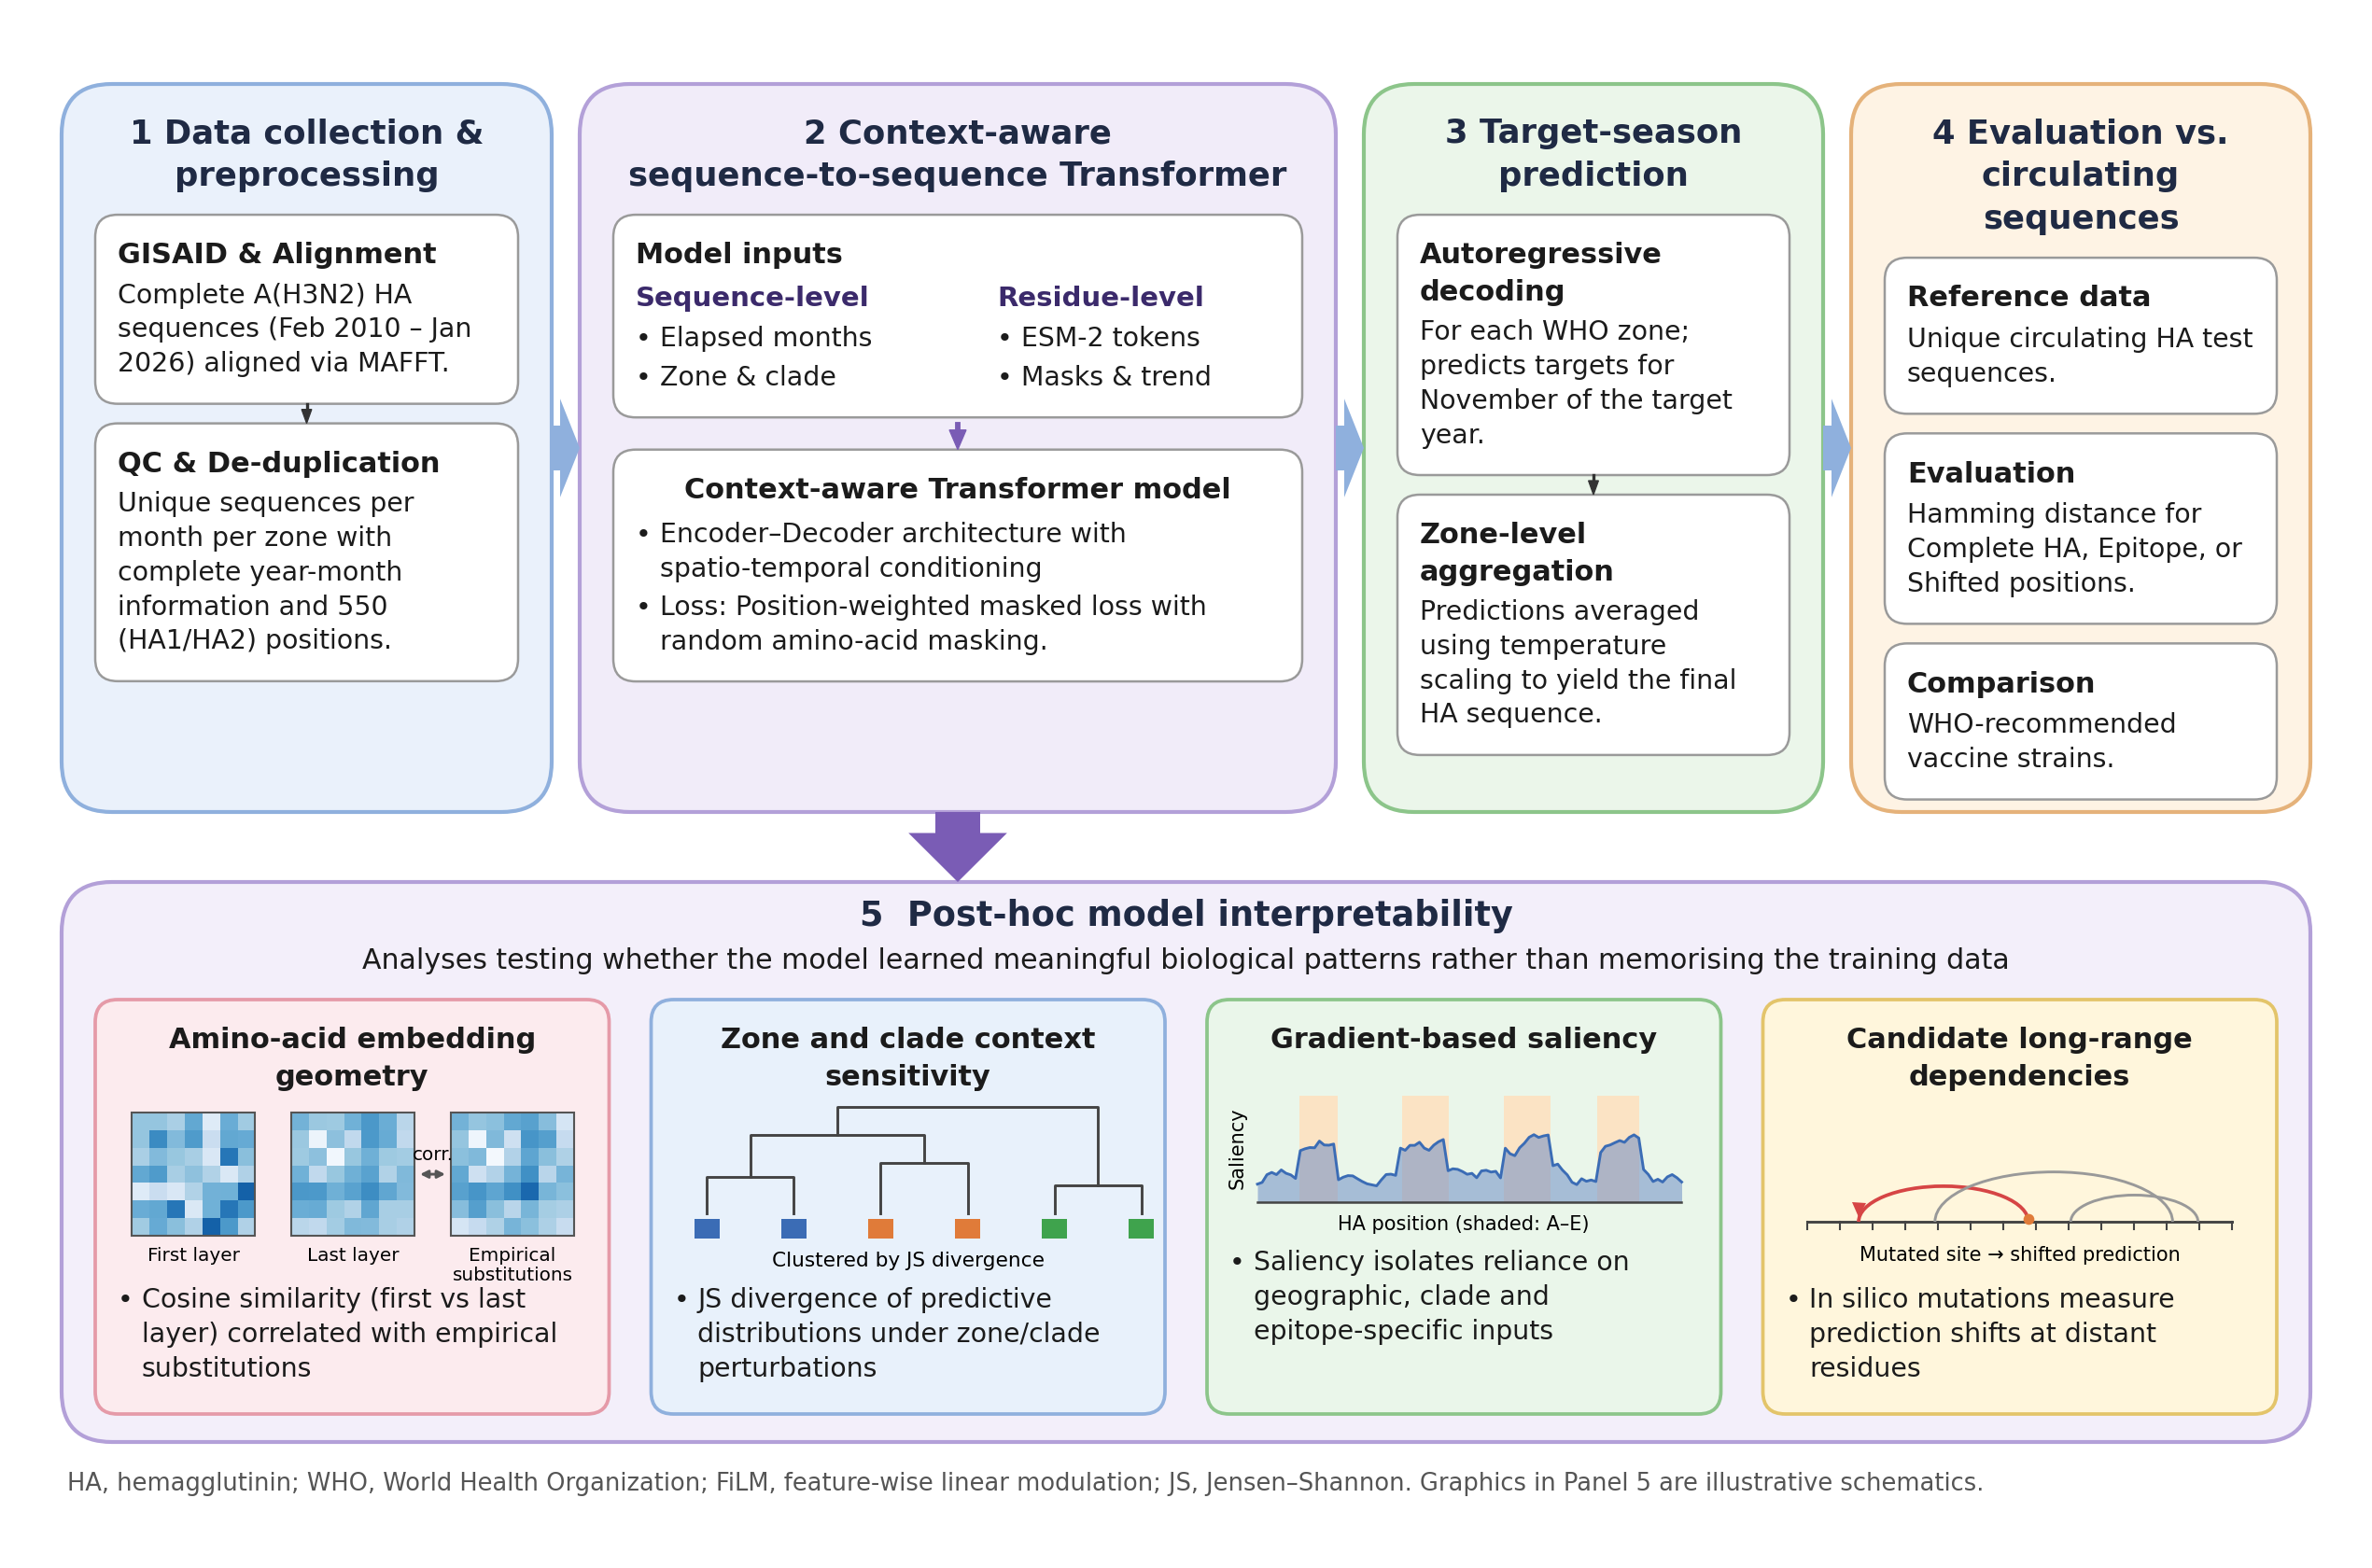

In [28]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.font_manager import FontProperties

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "pdf.fonttype": 42,        # embed editable text in the PDF
    "svg.fonttype": "none",
})


def draw_pipeline_overview(save_prefix="Figure1_pipeline_overview", show=True):
    """Figure 1: overview of the H3N2 HA forecasting pipeline (A4 portrait half page, 4 columns)."""
    # A4 portrait is 8.27 x 11.69 inches. Half page is 8.27 x 5.85 to 6.55 inches.
    # We use 1 data unit = 0.1 in.
    W, H = 82.7, 54.0
    fig = plt.figure(figsize=(8.27, 5.4), dpi=300)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.axis("off")
    meas = FigureCanvasAgg(Figure(dpi=300)).get_renderer()

    TXT, EC, LINE = "#1b1b1b", "#9a9a9a", "#333333"
    BLUE, ORANGE, GREEN, RED, PURPLE = "#3B6CB5", "#E07B39", "#3FA34D", "#D64545", "#8E5BB5"

    # ------------------------------------------------------------------ text engine
    def text_w(s, fs, wt="normal"):
        fp = FontProperties(size=fs, weight=wt)
        w, _, _ = meas.get_text_width_height_descent(s, fp, ismath=False)
        return w / 300.0 * 10.0

    def lh(fs):
        return fs * 1.3 / 7.2

    def wrap(s, width, fs, wt="normal"):
        out = []
        for para in s.split("\n"):
            cur = ""
            for wd in para.split(" "):
                t = (cur + " " + wd).strip()
                if not cur or text_w(t, fs, wt) <= width:
                    cur = t
                else:
                    out.append(cur)
                    cur = wd
            out.append(cur)
        return out

    def P(t, fs=7.3, wt="normal", c=TXT, b=False, st="normal", after=0.15, ha="left"):
        return dict(t=t, fs=fs, wt=wt, c=c, b=b, st=st, after=after, ha=ha)

    def G(h, fn):
        return dict(sp=h, fn=fn, after=0.0)

    def layout(parts, inner):
        items, hh = [], 0.0
        for p in parts:
            if "sp" in p:
                items.append((p, None, 0))
                hh += p["sp"] + p["after"]
                continue
            ind = text_w("• ", p["fs"], p["wt"]) if p["b"] else 0
            lines = wrap(p["t"], inner - ind, p["fs"], p["wt"])
            items.append((p, lines, ind))
            hh += lh(p["fs"]) * len(lines) + p["after"]
        return items, hh - parts[-1]["after"]

    def render(items, x, y, w):
        cy = y
        for p, lines, ind in items:
            if "sp" in p:
                p["fn"](x, cy, w)
                cy -= p["sp"] + p["after"]
                continue
            for i, ln in enumerate(lines):
                yy = cy - lh(p["fs"]) * (i + 0.5)
                kw = dict(fontsize=p["fs"], fontweight=p["wt"], fontstyle=p["st"], color=p["c"], va="center", zorder=6)
                if p["ha"] == "center":
                    ax.text(x + w / 2, yy, ln, ha="center", **kw)
                else:
                    if p["b"] and i == 0:
                        ax.text(x, yy, "•", ha="left", **kw)
                    ax.text(x + ind, yy, ln, ha="left", **kw)
            cy -= lh(p["fs"]) * len(lines) + p["after"]
        return cy

    def card(x, y, w, parts, fc="white", ec=EC, pad=0.8, h_fixed=None, lw=0.6):
        items, hc = layout(parts, w - 2 * pad)
        hh = h_fixed if h_fixed else hc + 2 * pad
        ax.add_patch(mp.FancyBboxPatch((x, y - hh), w, hh, boxstyle="round,pad=0,rounding_size=0.8",
                                       fc=fc, ec=ec, lw=lw, zorder=3))
        render(items, x + pad, y - pad, w - 2 * pad)
        return y - hh

    def arrow(pts, color=LINE, ls="-", lw=0.8, L=0.5, Wd=0.18, head=True):
        pts = list(pts)
        if head:
            (x0, y0), (x1, y1) = pts[-2], pts[-1]
            d = math.hypot(x1 - x0, y1 - y0)
            ux, uy = (x1 - x0) / d, (y1 - y0) / d
            bx, by = x1 - ux * L, y1 - uy * L
            ax.add_patch(mp.Polygon([(x1, y1), (bx - uy * Wd, by + ux * Wd), (bx + uy * Wd, by - ux * Wd)],
                                    closed=True, fc=color, ec=color, lw=0.3, zorder=6))
            pts[-1] = (bx, by)
        xs, ys = zip(*pts)
        ax.plot(xs, ys, color=color, ls=ls, lw=lw, zorder=5)

    # ------------------------------------------------------------------ panel frames layout
    # 4 columns for Panels 1-4
    TOP1, BOT1 = 52.0, 26.0
    PX = [1.2, 19.7, 47.7, 65.1]
    PW = [17.5, 27.0, 16.4, 16.4]

    def panel(i, title, fc, ec):
        x, w = PX[i], PW[i]
        ax.add_patch(mp.FancyBboxPatch((x, BOT1), w, TOP1 - BOT1, boxstyle="round,pad=0,rounding_size=1.8",
                                       fc=fc, ec=ec, lw=1.0, zorder=1))
        y = TOP1 - 1.0
        for ln in wrap(title, w - 2.4, 8.5, "bold"):
            ax.text(x + w / 2, y - lh(8.5) / 2, ln, ha="center", va="center", fontsize=8.5,
                    fontweight="bold", color="#1f2a44", zorder=6)
            y -= lh(8.5)
        return y - 0.6, x + 1.2, w - 2.4

    # ================================================================== PANEL 1
    y, x0, w0 = panel(0, "1  Data collection & preprocessing", "#EAF1FB", "#8FB0DD")
    steps = [
        ("GISAID & Alignment", "Complete A(H3N2) HA sequences (Feb 2010 – Jan 2026) aligned via MAFFT."),
        ("QC & De-duplication", "Unique sequences per month per zone with complete year-month information and 550 (HA1/HA2) positions.")
    ]
    for k, (hd, body) in enumerate(steps):
        yb = card(x0, y, w0, [P(hd, 7.3, "bold", after=0.15), P(body, 6.8)])
        if k < len(steps) - 1:
            arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 0.7)])
            y = yb - 0.7

    # ================================================================== PANEL 2
    y, x0, w0 = panel(1, "2  Context-aware sequence-to-sequence Transformer", "#F1ECF9", "#B3A0D8")
    
    colw = (w0 - 1.2) / 2
    left = [P("Sequence-level", 7.0, "bold", c="#3b2a6b", after=0.2),
            P("Elapsed months", 6.8, b=True),
            P("Zone & clade", 6.8, b=True)]
    right = [P("Residue-level", 7.0, "bold", c="#3b2a6b", after=0.2),
             P("ESM-2 tokens", 6.8, b=True),
             P("Masks & trend", 6.8, b=True)]
    
    iL, hL = layout(left, colw)
    iR, hR = layout(right, colw)

    def two_cols(x, yt, w):
        render(iL, x, yt, colw)
        render(iR, x + colw + 1.2, yt, colw)

    y = card(x0, y, w0, [P("Model inputs", 7.3, "bold", after=0.25), G(max(hL, hR), two_cols)]) - 0.25
    arrow([(x0 + w0 / 2, y), (x0 + w0 / 2, y - 0.9)], color="#7a5cb5", lw=1.4, L=0.7, Wd=0.3)
    y -= 0.9

    arch_text = [
        P("Context-aware Transformer model", 7.3, "bold", ha="center", after=0.3),
        P("Encoder–Decoder architecture with spatio-temporal conditioning", 6.8, b=True),
        P("Loss: Position-weighted masked loss with random amino-acid masking.", 6.8, b=True)
    ]
    card(x0, y, w0, arch_text)

    # ================================================================== PANEL 3
    y, x0, w0 = panel(2, "3  Target-season prediction", "#EBF6EA", "#8CC58A")
    cards3 = [
        ("Autoregressive decoding", "For each WHO zone; predicts targets for November of the target year."),
        ("Zone-level aggregation", "Predictions averaged using temperature scaling to yield the final HA sequence.")
    ]
    for k, (hd, body) in enumerate(cards3):
        yb = card(x0, y, w0, [P(hd, 7.3, "bold", after=0.15), P(body, 6.8)])
        if k < len(cards3) - 1:
            arrow([(x0 + w0 / 2, yb), (x0 + w0 / 2, yb - 0.7)])
            y = yb - 0.7

    # ================================================================== PANEL 4
    y, x0, w0 = panel(3, "4  Evaluation vs. circulating sequences", "#FEF3E4", "#E5B27A")
    cards4 = [
        ("Reference data", "Unique circulating HA test sequences."),
        ("Evaluation", "Hamming distance for Complete HA, Epitope, or Shifted positions."),
        ("Comparison", "WHO-recommended vaccine strains.")
    ]
    for k, (hd, body) in enumerate(cards4):
        yb = card(x0, y, w0, [P(hd, 7.3, "bold", after=0.2), P(body, 6.8)])
        y = yb - 0.7

    # ================================================================== PANEL 5
    Y5T, Y5B = 23.5, 3.5
    ax.add_patch(mp.FancyBboxPatch((1.2, Y5B), 80.3, Y5T - Y5B, boxstyle="round,pad=0,rounding_size=1.8",
                                   fc="#F3EFFA", ec="#B3A0D8", lw=1.0, zorder=1))
    ax.text(1.2 + 80.3 / 2, Y5T - 1.2, "5  Post-hoc model interpretability", ha="center", va="center",
            fontsize=8.8, fontweight="bold", color="#1f2a44", zorder=6)
    ax.text(1.2 + 80.3 / 2, Y5T - 2.8, "Analyses testing whether the model learned meaningful biological "
            "patterns rather than memorising the training data", ha="center", va="center", fontsize=7.2,
            color=TXT, zorder=6)

    def sym(rs, n=7):
        a = rs.rand(n, n)
        return (a + a.T) / 2

    def g_embed(x, yt, w):
        rs = np.random.RandomState(3)
        E = sym(rs)
        mats = [sym(rs), 0.8 * E + 0.2 * sym(rs), E]
        s = 4.4
        xs = [x + 0.5, x + 0.5 + s + 1.3, x + 0.5 + 2 * s + 2.6]
        names = ["First layer", "Last layer", "Empirical\nsubstitutions"]
        for xx, M, nm in zip(xs, mats, names):
            ax.imshow(M, extent=(xx, xx + s, yt - 0.3 - s, yt - 0.3), cmap="Blues", vmin=0, vmax=1.15,
                      interpolation="nearest", aspect="auto", zorder=5)
            ax.add_patch(mp.Rectangle((xx, yt - 0.3 - s), s, s, fc="none", ec="#555", lw=0.5, zorder=6))
            for i, ln in enumerate(nm.split("\n")):
                ax.text(xx + s / 2, yt - 0.3 - s - 0.7 - i * 0.7, ln, ha="center", va="center", fontsize=4.8, zorder=6)
        ax.annotate("", xy=(xs[2] - 0.2, yt - 0.3 - s / 2), xytext=(xs[1] + s + 0.2, yt - 0.3 - s / 2),
                    arrowprops=dict(arrowstyle="<|-|>", lw=0.7, color="#555", mutation_scale=4,
                                    shrinkA=0, shrinkB=0), zorder=6)
        ax.text((xs[1] + s + xs[2]) / 2, yt - 0.3 - s / 2 + 0.7, "corr.", ha="center", va="center", fontsize=4.8, zorder=6)

    def g_dendro(x, yt, w):
        yl = yt - 4.8
        lx = [x + 1.2 + i * 3.1 for i in range(6)]
        cols = [BLUE, BLUE, ORANGE, ORANGE, GREEN, GREEN]
        for xx, c in zip(lx, cols):
            ax.add_patch(mp.Rectangle((xx - 0.45, yl), 0.9, 0.7, fc=c, ec="none", zorder=5))
        y0 = yl + 0.9

        def u(xa, ya, xb, yb_, ytop):
            ax.plot([xa, xa, xb, xb], [ya, ytop, ytop, yb_], color="#444", lw=0.7, zorder=5)

        u(lx[0], y0, lx[1], y0, y0 + 1.3)
        u(lx[2], y0, lx[3], y0, y0 + 1.8)
        u(lx[4], y0, lx[5], y0, y0 + 1.0)
        u((lx[0] + lx[1]) / 2, y0 + 1.3, (lx[2] + lx[3]) / 2, y0 + 1.8, y0 + 2.8)
        u((lx[0] + lx[1] + lx[2] + lx[3]) / 4, y0 + 2.8, (lx[4] + lx[5]) / 2, y0 + 1.0, y0 + 3.8)
        ax.text(x + w / 2, yl - 0.8, "Clustered by JS divergence", ha="center", va="center",
                fontsize=5.2, zorder=6)

    def g_sal(x, yt, w):
        base = yt - 4.8
        n = 90
        xs = np.linspace(x + 1.0, x + w - 0.6, n)
        spans = [(0.10, 0.19), (0.34, 0.45), (0.58, 0.69), (0.80, 0.90)]
        for a, b in spans:
            ax.add_patch(mp.Rectangle((xs[0] + a * (xs[-1] - xs[0]), base), (b - a) * (xs[-1] - xs[0]), 3.8,
                                      fc="#FBE3C4", ec="none", zorder=4))
        rs = np.random.RandomState(5)
        prof = np.convolve(rs.rand(n), np.ones(4) / 4, mode="same") * 1.2 + 0.3
        for a, b in spans:
            i0, i1 = int(a * n), int(b * n)
            prof[i0:i1] += 1.2
        ax.fill_between(xs, base, base + prof, color="#6F8FC7", alpha=0.55, lw=0, zorder=5)
        ax.plot(xs, base + prof, color="#3B6CB5", lw=0.7, zorder=5)
        ax.plot([xs[0], xs[-1]], [base, base], color="#444", lw=0.6, zorder=5)
        ax.text(x + 0.3, base + 1.9, "Saliency", rotation=90, fontsize=5.0, ha="center", va="center", zorder=6)
        ax.text(x + w / 2, base - 0.8, "HA position (shaded: A–E)", ha="center", va="center",
                fontsize=5.0, zorder=6)

    def g_arcs(x, yt, w):
        base = yt - 4.2
        a0, a1 = x + 0.8, x + w - 0.8
        ax.plot([a0, a1], [base, base], color="#444", lw=0.7, zorder=5)
        for t in np.linspace(a0, a1, 14):
            ax.plot([t, t], [base, base - 0.25], color="#444", lw=0.5, zorder=5)
        pairs = [(0.12, 0.52, RED), (0.30, 0.86, "#999999"), (0.62, 0.92, "#999999")]
        for fa, fb, c in pairs:
            xa, xb = a0 + fa * (a1 - a0), a0 + fb * (a1 - a0)
            ax.add_patch(mp.Arc(((xa + xb) / 2, base), xb - xa, (xb - xa) * 0.42, theta1=0, theta2=180,
                                color=c, lw=0.9 if c == RED else 0.7, zorder=5))
        xa, xb = a0 + 0.12 * (a1 - a0), a0 + 0.52 * (a1 - a0)
        ax.plot(xa, base + 0.45, marker="v", ms=3.6, color=RED, mec="none", zorder=6)
        ax.plot(xb, base + 0.1, marker="o", ms=2.8, color=ORANGE, mec="none", zorder=6)
        ax.text(x + w / 2, base - 1.2, "Mutated site → shifted prediction", ha="center",
                va="center", fontsize=5.0, zorder=6)

    cw = (80.3 - 2.4 - 3 * 1.5) / 4
    ytop = Y5T - 4.2
    hfix = ytop - (Y5B + 1.0)
    
    cards5 = [
        ("Amino-acid embedding geometry", "#FCEBEE", "#E59AA8", g_embed, 6.2,
         [P("Cosine similarity (first vs last layer) correlated with empirical substitutions", fs=6.8, b=True)]),
        ("Zone and clade context sensitivity", "#E8F1FB", "#8FB0DD", g_dendro, 6.2,
         [P("JS divergence of predictive distributions under zone/clade perturbations", fs=6.8, b=True)]),
        ("Gradient-based saliency", "#EAF6EA", "#8CC58A", g_sal, 6.2,
         [P("Saliency isolates reliance on geographic, clade and epitope-specific inputs", fs=6.8, b=True)]),
        ("Candidate long-range dependencies", "#FFF6DC", "#E3C46A", g_arcs, 6.2,
         [P("In silico mutations measure prediction shifts at distant residues", fs=6.8, b=True)]),
    ]
    for k, (ttl, fc, ec, fn, gh, bl) in enumerate(cards5):
        xk = 1.2 + 1.2 + k * (cw + 1.5)
        card(xk, ytop, cw, [P(ttl, 7.3, "bold", ha="center", after=0.3), G(gh, fn), P("", 1.0, after=0.0)] + bl,
             fc=fc, ec=ec, h_fixed=hfix, lw=0.9)

    # ------------------------------------------------------------------ flow arrows
    def block_arrow(xc, yc, dx=0.0, dy=0.0, color="#8FB0DD", wd=1.6):
        if dx != 0:
            ax.add_patch(mp.FancyArrow(xc - dx / 2, yc, dx, 0, width=wd, head_width=wd*2.2, head_length=abs(dx)*0.7,
                                       length_includes_head=True, fc=color, ec="none", zorder=7))
        elif dy != 0:
            ax.add_patch(mp.FancyArrow(xc, yc - dy / 2, 0, dy, width=wd, head_width=wd*2.2, head_length=abs(dy)*0.7,
                                       length_includes_head=True, fc=color, ec="none", zorder=7))

    ymid = (TOP1 + BOT1) / 2
    # Arrows between P1 -> P2, P2 -> P3, P3 -> P4
    block_arrow(PX[0] + PW[0] + 0.5, ymid, dx=1.0)
    block_arrow(PX[1] + PW[1] + 0.5, ymid, dx=1.0)
    block_arrow(PX[2] + PW[2] + 0.5, ymid, dx=1.0)
    
    # Arrow from P2 down to Panel 5
    block_arrow(PX[1] + PW[1] / 2, (BOT1 + Y5T) / 2, dy=-(BOT1 - Y5T), color="#7a5cb5")

    # ------------------------------------------------------------------ footnote
    foot = ("HA, hemagglutinin; WHO, World Health Organization; FiLM, feature-wise linear modulation; JS, Jensen–Shannon. "
            "Graphics in Panel 5 are illustrative schematics.")
    for i, ln in enumerate(wrap(foot, 80.0, 6.2)):
        ax.text(1.4, 2.0 - i * lh(6.2), ln, fontsize=6.2, color="#555555", va="center", zorder=6)

    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    if save_prefix:
        fig.savefig(f"{save_prefix}.pdf", bbox_inches='tight')
        fig.savefig(f"{save_prefix}.png", dpi=300, bbox_inches='tight')
    if show:
        plt.show()
    return fig


if __name__ == "__main__":
    draw_pipeline_overview()